In [4]:
##### Figure 5: country exposure butterfly chart

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib import gridspec

In [5]:
##### LOAD DATA

ROOT = Path.cwd().parent
EXPOSURE_DIR = ROOT / "Results" / "30x30"

# keep_default_na=False so Namibia's ISO3 code "NA" is not read as missing
read_kwargs = dict(keep_default_na=False, na_values=[""])
country_df = pd.read_csv(EXPOSURE_DIR / "country_exposure_long.csv", **read_kwargs)
ci_df = pd.read_csv(EXPOSURE_DIR / "country_exposure_ci.csv", **read_kwargs)

# indexed by (ISO3, Variable); columns = (metric, quantile)
ci_lookup = ci_df.pivot_table(
    index=["ISO3", "Variable"],
    columns="Quantile",
    values=["Pct_of_global", "Pct_of_national"],
    aggfunc="sum",
)

# country name lookup
name_lookup = (
    country_df[["ISO3", "Country"]]
    .drop_duplicates("ISO3")
    .set_index("ISO3")["Country"]
)

FIG_DIR = ROOT / "Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [6]:
##### STYLING

COLORS = {
    "Capital": "#2F7C87",
    "Labor": "#C96A3B",
    "Production": "#6B7280",
    "Area": "#8E5B9F",
}

STATUS_COLORS = {
    "Additional priority": "#D9D9D9",
    "Already in PA": "#595959",
}

TITLE_FS = 8   # subplot titles
LABEL_FS = 7   # axis and legend labels
TICK_FS = 6    # tick labels

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica"],
    "font.size": TICK_FS,
    "axes.titlesize": TITLE_FS,
    "axes.labelsize": LABEL_FS,
    "xtick.labelsize": TICK_FS,
    "ytick.labelsize": TICK_FS,
    "legend.fontsize": LABEL_FS,
})

/var/folders/48/ky2jtbmj31bfj15cr5gq480w0000gn/T/ipykernel_93080/1134154055.py:135: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.93])


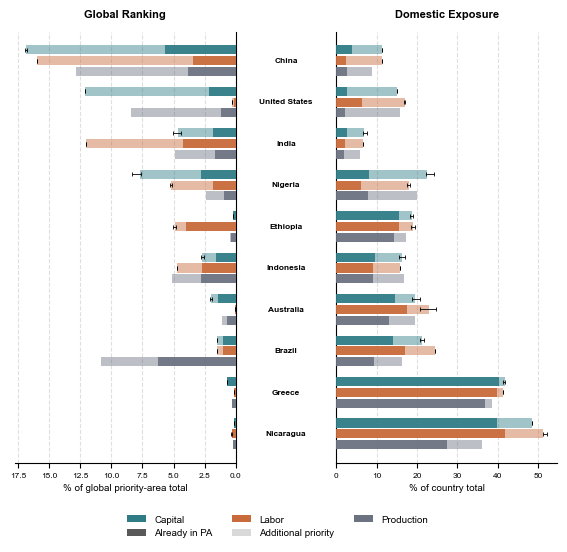

In [7]:
##### FIGURE 5

# manually specify which countries to include
selected_countries = ["CHN", "USA", "IND", "NGA", "ETH", "IDN", "AUS", "BRA", "GRC", "NIC"]

def plot_country_butterfly(country_df, country_list, ci_lookup, name_lookup):

    def get_values(iso3, variable, pct_col):
        sub = country_df[
            (country_df["ISO3"] == iso3) & (country_df["Variable"] == variable)
        ]
        already = sub.loc[sub["Class"] == "Already in PA", pct_col].sum()
        additional = sub.loc[sub["Class"] == "Additional priority", pct_col].sum()
        return already, additional

    # error bars
    def get_ci(iso3, variable, metric):
        try:
            lo = ci_lookup.loc[(iso3, variable), (metric, "p10")]
            hi = ci_lookup.loc[(iso3, variable), (metric, "p90")]
        except KeyError:
            return None
        if np.isnan(lo) or np.isnan(hi):
            return None
        return lo, hi

    def add_total_errorbar(ax, y, total, ci):
        if ci is None:
            return
        lo, hi = ci
        ax.errorbar(
            total, y,
            xerr=[[max(total - lo, 0)], [max(hi - total, 0)]],
            fmt="none", ecolor="black", elinewidth=0.6, capsize=1.5, capthick=0.6,
            zorder=5,
        )

    n = len(country_list)
    bar_h = 0.22
    offset = bar_h + 0.04

    fig = plt.figure(figsize=(7, 0.4 * n + 1.6))
    gs = gridspec.GridSpec(1, 3, width_ratios=[4, 1.5, 4], wspace=0.05)

    ax_left = fig.add_subplot(gs[0])
    ax_mid = fig.add_subplot(gs[1], sharey=ax_left)
    ax_right = fig.add_subplot(gs[2], sharey=ax_left)

    y_positions = np.arange(n)[::-1]

    for y, iso3 in zip(y_positions, country_list):

        for variable, y_off in [
            ("Capital", offset),
            ("Labor", 0),
            ("Production", -offset),
        ]:

            already_g, additional_g = get_values(iso3, variable, "Pct_of_global")
            already_n, additional_n = get_values(iso3, variable, "Pct_of_national")

            # global distribution
            ax_left.barh(
                y + y_off, already_g, bar_h,
                color=COLORS[variable], alpha=0.95, zorder=3,
            )
            ax_left.barh(
                y + y_off, additional_g, bar_h, left=already_g,
                color=COLORS[variable], alpha=0.45, zorder=3,
            )
            add_total_errorbar(
                ax_left, y + y_off, already_g + additional_g,
                get_ci(iso3, variable, "Pct_of_global"),
            )

            # national exposure
            ax_right.barh(
                y + y_off, already_n, bar_h,
                color=COLORS[variable], alpha=0.95, zorder=3,
            )
            ax_right.barh(
                y + y_off, additional_n, bar_h, left=already_n,
                color=COLORS[variable], alpha=0.45, zorder=3,
            )
            add_total_errorbar(
                ax_right, y + y_off, already_n + additional_n,
                get_ci(iso3, variable, "Pct_of_national"),
            )

    # axes
    ax_left.set_xlabel("% of global priority-area total", fontsize=LABEL_FS)
    ax_left.invert_xaxis()
    ax_left.spines[["top", "left"]].set_visible(False)
    ax_left.grid(axis="x", linestyle="--", alpha=0.4, zorder=0)
    ax_left.set_axisbelow(True)
    ax_left.set_title("Global Ranking", fontsize=TITLE_FS, fontweight="bold", pad=10)
    ax_left.yaxis.set_visible(False)

    ax_right.set_xlabel("% of country total", fontsize=LABEL_FS)
    ax_right.spines[["top", "right"]].set_visible(False)
    ax_right.grid(axis="x", linestyle="--", alpha=0.4, zorder=0)
    ax_right.set_axisbelow(True)
    ax_right.set_title("Domestic Exposure", fontsize=TITLE_FS, fontweight="bold", pad=10)
    ax_right.yaxis.set_visible(False)

    ax_mid.axis("off")

    for y, iso3 in zip(y_positions, country_list):
        ax_mid.text(
            0.5, y, name_lookup.get(iso3, iso3),
            ha="center", va="center", fontsize=TICK_FS, fontweight="bold",
        )

    ax_mid.set_xlim(0, 1)
    ax_left.set_ylim(-0.7, n - 0.3)

    # legend
    legend_elements = [
        Patch(facecolor=COLORS["Capital"], label="Capital"),
        Patch(facecolor=STATUS_COLORS["Already in PA"], label="Already in PA"),
        Patch(facecolor=COLORS["Labor"], label="Labor"),
        Patch(facecolor=STATUS_COLORS["Additional priority"], label="Additional priority"),
        Patch(facecolor=COLORS["Production"], label="Production"),
    ]

    fig.legend(
        handles=legend_elements,
        loc="lower center",
        ncol=3,
        bbox_to_anchor=(0.5, -0.04),
        frameon=False,
        fontsize=LABEL_FS,
    )

    plt.tight_layout(rect=[0, 0, 1, 0.93])

    plt.savefig(
        FIG_DIR / "Figure_5_country_exposure.tiff",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

plot_country_butterfly(country_df, selected_countries, ci_lookup, name_lookup)